By: Max Cooper and Shane Brosnan

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

In [44]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


> We would rather not get the balloon since those who got the balloon had a lower survival rate than those who did not based on the point estimate of the ATE. Those with the balloon survived only 24.5% (95 out of 388) of the time whereas those who did not get the balloon survived at a slightly higher 25.4% (99 out of 389) of the time, giving us the ATE of 24.5-25.4 = -0.09 ~ -0.1. Based on this point estimate, we would rather not get the pump and receive the conservative treatment (be in group B).

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [45]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

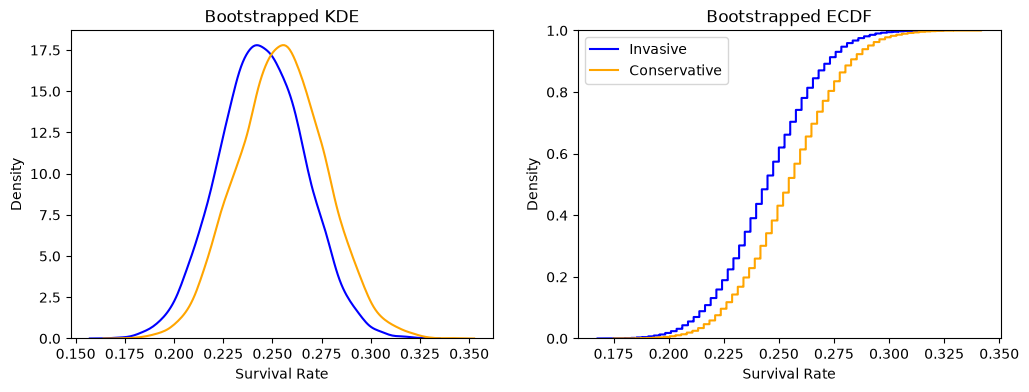

In [46]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

> From the density, we see that a random sample of invasively treated patients are less likely to survive compared to a random sample of conservatively treated patients. Looking at the ECDF, we can quantify this trend. The median survival rate of an invasively treated sample is approximately 24% and the median survival rate of a conservatively treated sample is about 25%. Unlike some of the ECDFs we've seen in the past, the lines never cross, so at every quantile, the conservative survival rate is higher than that quantile survival rate of invasive treatments. However, this difference is small.

**4.** Make a plot of the KDE and ECDF for the ATE. 

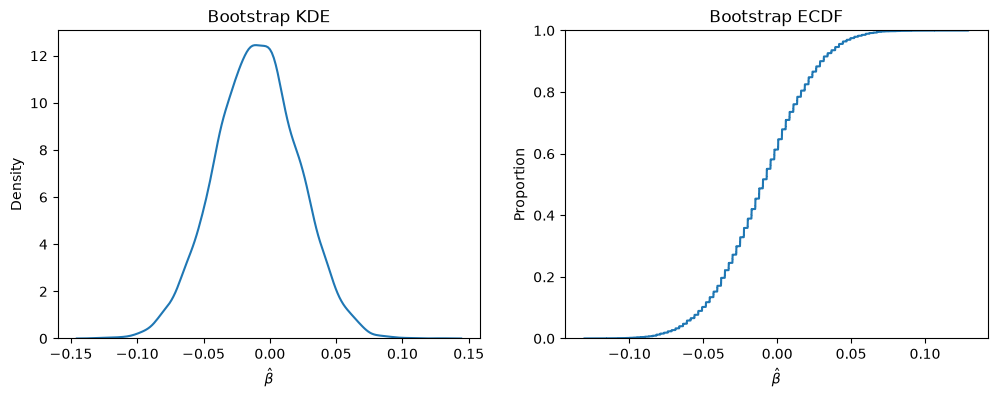

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [48]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06116662  0.04181353]
95% CI: [-0.07142968  0.04961837]
99% CI: [-0.08943766  0.0675803 ]


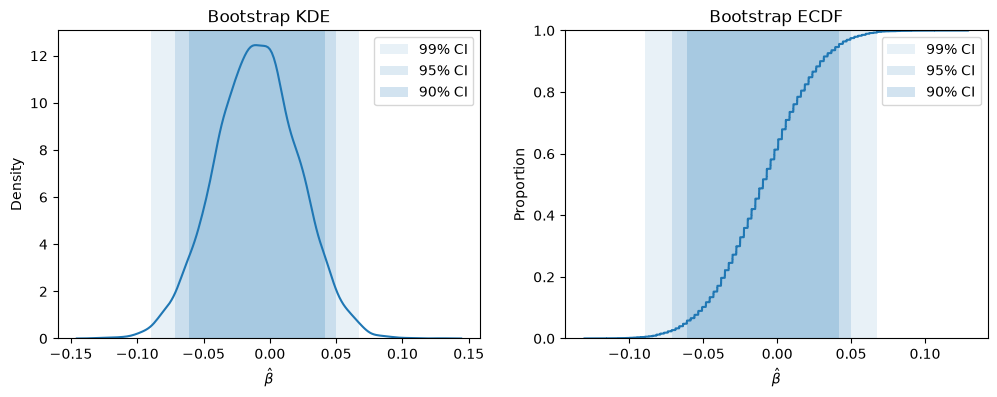

In [49]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

> Since the average ATE was so close to 0, estimating the ATE between the two groups with confidence does not provide enough evidence for us to reject the null hypothesis that the difference is zero. The 90%, 95%, and 99% CI are [−0.061, 0.042], [−0.071, 0.052], and [−0.092, 0.070] respectively. All three confidence intervals contain 0 so we fail to reject the null hypothesis that the effect size is zero at the 10%, 5%, and 1% significance levels. Furthermore, because no interval excludes 0, there is no level at which we can reject the null hypothesis. Again, we can see that point estimate of ATE favors the conservative groups because more of the coverage is in the negative range (as seen in the bootstrap ECDF and KDE plots), but this small favoring is not significant. That said, even though we fail to reject the null hypothesis does not prove the pump has no effect, rather it means this sample data cannot pick up a significant distinction from a zero effect which may change with more data or a different trial method.

**6.** What have we learned about inserting balloons into hearts?

> There is not sufficient evidence to conclude that using the different treatment will lead to a different survival rate. In the trial, patients who did not receive the ballon had a slightly higher survival rate, per the point estimate ATE of -0.1. However, this was not a significant result as none of the confidence intervals excluded 0, meaning we could not reject the null hypothesis that the difference in survival is zero.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [50]:
# 1.

# loading in the data
df = pd.read_csv('./data/diabetes.csv')

# creating cross tab for outcomes of the three groups
print(pd.crosstab( df['treatment'], df['outcome']), '\n')

# pulling successful outcomes
df['success'] = (df['outcome'] == 'success').astype(int)
# computing the average outcomes for each of the three groups
met_avg = df.loc[ df['treatment'] == 'met', 'success'].mean()
rosi_avg = df.loc[ df['treatment'] == 'rosi', 'success'].mean()
life_avg = df.loc[ df['treatment'] == 'lifestyle', 'success'].mean()

# printing the results
print('Metformin average outcome: ', np.round(met_avg, 3))
print('Rosiglitazone average outcome: ', np.round(rosi_avg, 3))
print('Lifestyle average outcome: ', np.round(life_avg, 3))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

Metformin average outcome:  0.483
Rosiglitazone average outcome:  0.614
Lifestyle average outcome:  0.534


> The Rosiglitazone treatment had the highest success rate, with a full diabetes prevention rate of 61.4% (143/233). The Lifestyle treatment had the second highest prevention of diabetes rate of 53.4% (125/234). Lastly, the Metformin treatment had the lowest success rate of 48.3% (112/232). Based on this alone, we are inclined to believe that Rosiglitazone is the best treatment.

In [51]:
# 2.

# bootstrapping the outcomes for the three groups 10,000 times (resampling within the arms)
# using code from question 2 in part 1 and adapting

## Bootstrapping:
np.random.seed(2026) # Added: makes results reproducible across runs
R = 10_000

# subsetting the data to each treatment type
df_met = df.loc[ df['treatment'] == 'met',:]
df_rosi = df.loc[ df['treatment'] == 'rosi',:]
df_life = df.loc[ df['treatment'] == 'lifestyle',:]

# initializing empty lists to store results
outcome_met = []
outcome_rosi = []
outcome_life = []
# initializing empty list to store the ates between treatments
# added when we got to part 2 question 4
ate_met_rosi = []
ate_met_life = []
ate_rosi_life = []

for t in range(R):
    # bootstrap resampling for each treatment group
    df_mt = df_met.sample(frac=1.0, replace=True)
    df_rt = df_rosi.sample(frac=1.0, replace=True)
    df_lt = df_life.sample(frac=1.0, replace=True)

    # computing the mean outcome for each treatment group from the bootstrap samples   
    omt = df_mt['success'].mean() # Mean outcome for met
    ort = df_rt['success'].mean() # Mean outcome for rosi
    olt = df_lt['success'].mean() # Mean outcome for lifestyle

    # computing the average treatment effect for each pairwise comparison
    # added when we got to part 2 question 4
    ate_met_rosi.append(omt - ort)
    ate_met_life.append(omt - olt)
    ate_rosi_life.append(ort - olt)

    # saving the results
    outcome_met.append(omt) # Save new value
    outcome_rosi.append(ort) # Save new value
    outcome_life.append(olt) # Save new value


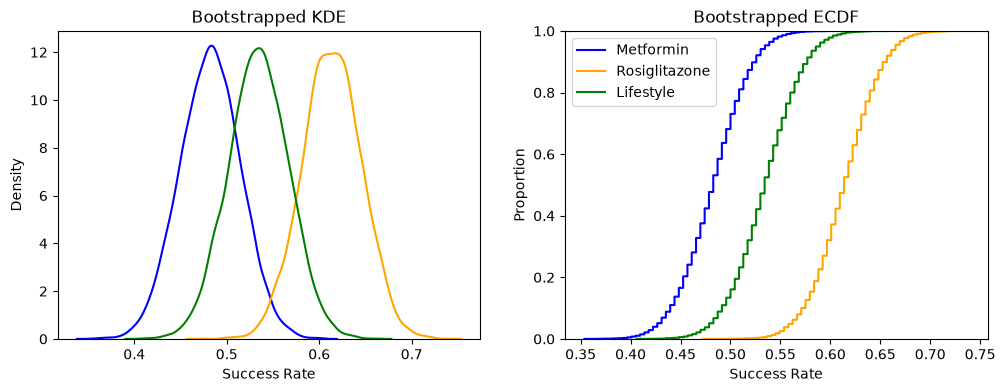

In [52]:
# 3. 

# plotting the three densities on one plot and three distribution on another plot
# adapting code from question 3 in part 1

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Metformin', color='blue', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[0])
sns.kdeplot(outcome_life, label='Lifestyle', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='Metformin', color='blue', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[1])
sns.ecdfplot(outcome_life, label='Lifestyle', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

plt.legend()
# saving the fig with help of Claude to include in report
plt.savefig('./src/p2q3_success_rates.png', dpi=150, bbox_inches='tight')
plt.show()

> All three bootstrap distributions have a similar bell shape and spread, but they differ based on where they are centered: Metformin around 48%, Lifestyle around 53%, and Rosiglitazone around 61% which matches the average success rate we found before. Looking at the three ECDF's, they do not cross at all. This means that at every quantile, Rosiglitazone has the highest success rate, followed by Lifestyle, followed by Metformin. This all aligns with what we expected based on our cross tab table in question 1. However, just because we see the lack of crossing in the ECDF's does not mean that we are positive this is the correct ordering of effectiveness. As we can see in the bootstrapped KDE plots, there is still overlapping between all three treatments so we cannot be too certain just yet about which treatment is truely better based on the data.

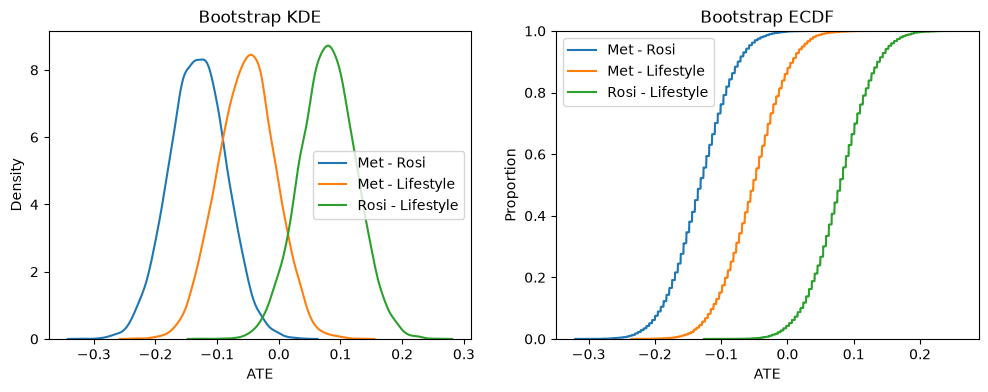

In [53]:
# 4. 

# making KDE and ECDF plots of all three comparisons
# adapting code from question 4 in part 1

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_met_rosi, label='Met - Rosi', ax=ax[0])
sns.kdeplot(ate_met_life, label='Met - Lifestyle', ax=ax[0])
sns.kdeplot(ate_rosi_life, label='Rosi - Lifestyle', ax=ax[0])
ax[0].set_xlabel("ATE")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate_met_rosi, label='Met - Rosi', ax=ax[1])
sns.ecdfplot(ate_met_life, label='Met - Lifestyle', ax=ax[1])
sns.ecdfplot(ate_rosi_life, label='Rosi - Lifestyle', ax=ax[1])
ax[1].set_xlabel("ATE")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()
# saving plots with Claude to include them in report
plt.savefig('./src/p2q4_ates.png', dpi=150, bbox_inches='tight')
plt.show()

 For: Met - Rosi
90% CI: [-0.2083025  -0.05781042]
95% CI: [-0.22136303 -0.0408641 ]
99% CI: [-0.2471142  -0.01065552] 



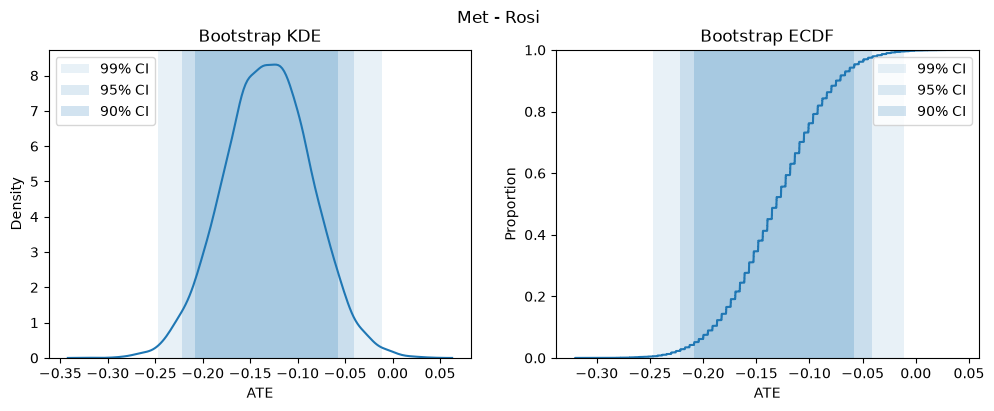

 For: Met - Lifestyle
90% CI: [-0.1287209  0.0255305]
95% CI: [-0.14161509  0.03846154]
99% CI: [-0.17141928  0.06852361] 



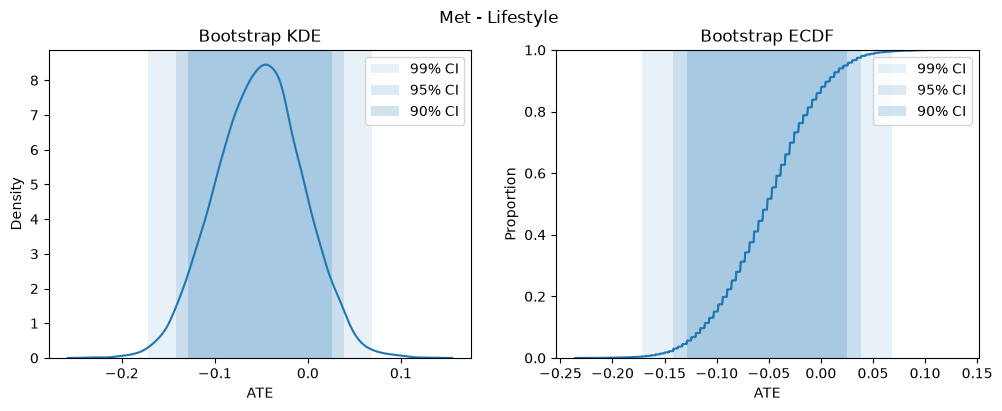

 For: Rosi - Lifestyle
90% CI: [0.00254943 0.1524348 ]
95% CI: [-0.01034491  0.16943619]
99% CI: [-0.03607727  0.19516901] 



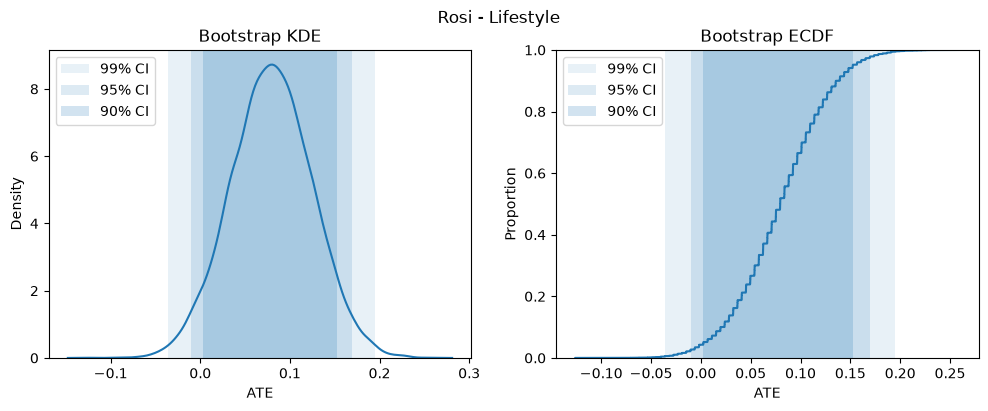

In [54]:
# 5.

# computing confidence intervals for each pairwise ATE based on ECDF (percentile bootstrap)
# adapted from part 1 question 5 to now loop over names/ates

# defining the comparisons and their ate to loop over
comparisons = {'Met - Rosi': ate_met_rosi, 'Met - Lifestyle': ate_met_life, 'Rosi - Lifestyle': ate_rosi_life}

for comp, ate in comparisons.items():
    # Percentile bootstrap confidence intervals
    ci90 = np.quantile(ate, [.05, .95])
    ci95 = np.quantile(ate, [.025, .975])
    ci99 = np.quantile(ate, [.005, .995])

    # print line to see which CI's go to which comparison
    print(f" For:", comp) 
    print(f"90% CI: {ci90}")
    print(f"95% CI: {ci95}")
    print(f"99% CI: {ci99}", '\n')

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ## KDE
    sns.kdeplot(ate, ax=ax[0])

    ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

    #ax[0].set_xlabel(r"$\hat{\beta}$")
    ax[0].set_xlabel("ATE")
    ax[0].set_title("Bootstrap KDE")
    ax[0].legend()

    ## ECDF
    sns.ecdfplot(ate, ax=ax[1])

    ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

    ax[1].set_xlabel("ATE")
    ax[1].set_title("Bootstrap ECDF")
    ax[1].legend()

    # adding title to subplots now that his is a loop
    fig.suptitle(comp)
    # need this command to plot since we are now looping
    plt.show()

> Looking at the first comparison between Metformin and Rosiglitazone, we have that all of the confidence intervals exclude 0 (ex. 95% CI is [-0.221, -0.041]). Because 0 is outside all of the confidence intervals, we can reject the null hypothesis that Metformin has the same effect as Rosiglitazone at our three confidence levels (Ros does better than met since it is on the negative side of 0). Now looking at the second comparison between Metformin and Lifestyle, we have that all of the confidence intervals include 0. Since 0 lays within all of the confidence intervals, we fail to reject the null hypothesis that the difference in these treatments is zero at all 3 confidence levels. Lastly, looking at Rosiglitazone and Lifestyle, we have that 0 is not included in the 90% CI but that it is included at in the 95% and 99% CI's. So, at a 90% confidence level, we can reject the null hypothesis that the difference in treatments is 0 but at higher levels than that we cannot reject the null. Putting this together, the only difference that is statistically significant at every level is Rosiglitazone versus Metformin. Rosiglitazone's higher success rate than Lifestyle is significant depending on the confidence level, but still has a positive ATE suggesting that on average it is a better treatment. Overall, Rosiglitazone appears to be the most effective intervention.

# Report (Q6)

## (Report with images/plots it is report.md)
## (please grade that one with the graphs instead)

This report will review a randomized controlled trial in which 699 pre-diabetic patients were assigned to one of three intervention treatments, all with the purpose of slowing the progression of type-2 diabetes. The three treatments were Metformin with 232 patients, Rosiglitazone with 233 patients, and lifestyle adjustments with 234 patients. Outcomes for the treatments were deemed either a success or failure (binary) based on whether or not the pre-diabetic patients progressed to having type-2 diabetes. The effectiveness of each individual treatment is captured by its average success rates. Determining if one treatment outperforms another is done through computing average treatment effect (ATE), and seeing how often those ATE estimates excludes 0 at differing confidence levels using 10,000 bootstrapped samples. Therefore, inference on treatment effectiveness is based on percentile bootstrap confidence intervals.

Starting with the basics, we can see the average success rate for each treatment group below in Table 1 (pulled for Part 2 Question 1). Here, Rosiglitazone has the highest observed success rate at 61.4%, followed by Lifestyle at 53.4%, and lastly by Metformin at 48.3%. This is basic evidence that Rosiglitazone is the most effective treatment, but to be sure we take it a step further by looking at the distribution of these success rates when we bootstrap them. From the output in Part 2 Question 3, we can observe the bootstrapped KDE and ECDF plots of each treatment groups success rate. The KDE plots show that the densities are centered around the full sample success rates, and that each group has very similar spread. The ECDF plots never cross, implying that at every quantile Rosiglitazone has the highest success rate and Metformin has the lowest success rate. These three pieces of evidence come together to tell the story that Rosiglitazone is the most effective treatment for preventing type-2 diabetes, but to be even more certain we expand upon this by comparing the effectiveness between treatments.


Table 1: Success rates by treatment group

| Arm | N | Successes | Success rate |
|---|---|---|---|
| Metformin | 232 | 112 | 48.3% |
| Rosiglitazone | 233 | 143 | 61.4% |
| Lifestyle | 234 | 125 | 53.4% |


After comparing the success rates between treatments groups, results on the ATE's and the confidence intervals at different significant levels can be found in Table 2 (pulled from Part 2 Question 5). Looking at the first row, we see that Rosiglitazone is about 13 percentage points more successful than Metformin, and that this outperformance is statistically significant at all three confidence levels because 0 is not included in the CI's. This is our strongest finding from the comparisons: Rosiglitazone significantly outperforms Metformin at the 99% confidence level. Moving onto the next comparison, the Metformin–Lifestyle ATE is -0.05 which means that the Lifestyle treatment is 5 percentage points more effective than the Metformin treatment. However, this ATE is so close to 0 and 0 is included in all the confidence intervals, meaning that at no confidence level can we reject the null that these treatments have the same effect. Lastly, in the Rosiglitazone-Lifestyle comparison we find an ATE of 0.08, saying Rosiglitazone is 8% more effective than lifestyle. Interestingly, 0 is not included in the CI at 90%, but it is at 95% and 99%, meaning that we can only reject the null of them having the same effectiveness at the lowest confidence level. Having tested the three pairwise comparisons, the narrative that Rosiglitazone is the best treatment persists but we cannot say this with full certainty since we do not have enough evidence to reject the null at every confidence level for the two alternative treatments, or even a non-treatment.


Table 2: Pairwise ATE's and percentile bootstrap confidence intervals

| Comparison | ATE | 90% CI | 95% CI | 99% CI | Reject H0 (ATE = 0) |
|---|---|---|---|---|---|
| Metformin − Rosiglitazone | −0.13 | [−0.208, −0.058] | [−0.221, −0.041] | [−0.247, −0.011] | All confidence levels |
| Metformin − Lifestyle | −0.05 | [−0.129, 0.026] | [−0.142, 0.038] | [−0.171, 0.069] | No confidence levels |
| Rosiglitazone − Lifestyle | +0.08 | [0.003, 0.152] | [−0.010, 0.169] | [−0.036, 0.195] | Only 10% confidence level |


Putting this all together, the trial supports prescribing Rosiglitazone over the other two options, outperforming Metformin with statistical significance and only slightly outperforming Lifestyle at the 90% confidence level. That said, this trial and data has some limitations. For example, the data only uses a binary outcome for success which may not capture the full picture, and treatments may prolong the progression from pre-diabetes to type-2 diabetes rather than preventing it which may not be caught if the binary is determined prematurely. More importantly, we do not have data on the success rate for a non-treatment group so we can only compare the effectiveness of treatments amongst themselves and cannot determine the effectiveness relative to a patient not on a treatment plan. Therefore, the results of this trial are enough to recommend the uptake of Rosiglitazone as a treatment for pre-diabetes conditional since it is consistently the best performing group across our analysis, but not enough to give us full certainty.